In [1]:
# Student Details
# Name : Vaishnavi Chaudhari
# Roll no : 11
# Sec : C
# Subject : DSS

In [2]:
import pandas as pd
import numpy as np

In [3]:
# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
import os

In [5]:
os.getcwd()

In [6]:
os.chdir(r'C:\Users\Vaishnavi\Downloads\DSS')

In [7]:
data=pd.read_csv("Student Depression Dataset_Multiclass classification.csv")

In [8]:
data.head()

In [9]:
data.tail()

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  str    
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  str    
 4   Profession                             27901 non-null  str    
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  str    
 11  Dietary Habit

In [11]:
data.describe()

In [12]:
data.shape

In [13]:
data.size

In [14]:
data.ndim

In [15]:
# check Missing Value by record 

data.isna()

In [16]:
data.isna().any()

In [17]:
data.isna().sum()

In [18]:
# Remove extra spaces from column names
data.columns = data.columns.str.strip()

print("Dataset Shape :", data.shape)
print("\nColumns:")
print(data.columns)

Dataset Shape : (27901, 20)

Columns:
Index(['id', 'Gender', 'Age', 'City', 'Profession', 'Academic Pressure',
       'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction',
       'Sleep Duration', 'Dietary Habits', 'Degree',
       'Have you ever had suicidal thoughts ?', 'Work/Study Hours',
       'Financial Stress', 'Family History of Mental Illness', 'Depression',
       'Class', 'Type'],
      dtype='str')


In [19]:
# -------------------------------------------
# Handle Missing Values
# -------------------------------------------

for col in data.columns:

    if not pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(data[col].mode()[0])

    else:
        data[col] = data[col].fillna(data[col].median())

In [20]:
print(data[['Type']].head(10))

  Type
0  MDD
1   SD
2   SD
3   PD
4  MDD
5  SAD
6  MDD
7  SAD
8  SAD
9  MDD


In [21]:
# -------------------------------------------
# Convert all categorical columns to numeric
# -------------------------------------------

label_encoders = {}

for col in data.select_dtypes(include=['object']).columns:

    le = LabelEncoder()

    data[col] = le.fit_transform(data[col].astype(str))

    label_encoders[col] = le

print("\nData Types After Transformation")
print(data.dtypes)



Data Types After Transformation
id                                         int64
Gender                                     int64
Age                                      float64
City                                       int64
Profession                                 int64
Academic Pressure                        float64
Work Pressure                            float64
CGPA                                     float64
Study Satisfaction                       float64
Job Satisfaction                         float64
Sleep Duration                             int64
Dietary Habits                             int64
Degree                                     int64
Have you ever had suicidal thoughts ?      int64
Work/Study Hours                         float64
Financial Stress                           int64
Family History of Mental Illness           int64
Depression                                 int64
Class                                      int64
Type                                

In [22]:
print(data[['Type']].head(10))

   Type
0     1
1     4
2     4
3     2
4     1
5     3
6     1
7     3
8     3
9     1


In [23]:
# Classification
# -------------------------------------------
# Features and Target (Class)
# -------------------------------------------

X = data.drop('Class', axis=1)
y = data['Class']

In [24]:
# -------------------------------------------
# Train-Test Split
# -------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [25]:
# -------------------------------------------
# Build Random Forest Classifier for Class
# -------------------------------------------

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

In [26]:
# -------------------------------------------
# Prediction
# -------------------------------------------

y_pred = model.predict(X_test)

In [27]:
# -------------------------------------------
# Evaluation for Class
# -------------------------------------------

print('\nAccuracy :', accuracy_score(y_test, y_pred))

print('\nClassification Report\n')
print(classification_report(y_test, y_pred))

print('\nConfusion Matrix\n')
print(confusion_matrix(y_test, y_pred))


Accuracy : 0.8604192796989787

Classification Report

              precision    recall  f1-score   support

           0       0.82      1.00      0.90      1839
           1       0.99      0.59      0.74      1854
           2       0.84      1.00      0.91      1888

    accuracy                           0.86      5581
   macro avg       0.88      0.86      0.85      5581
weighted avg       0.88      0.86      0.85      5581


Confusion Matrix

[[1833    6    0]
 [ 410 1085  359]
 [   1    3 1884]]


In [28]:
for col, encoder in label_encoders.items():
    print(f"\n{col}")
    for original, encoded in zip(encoder.classes_, encoder.transform(encoder.classes_)):
        print(f"{original} --> {encoded}")


Gender
Female --> 0
Male --> 1

City
'Less Delhi' --> 0
'Less than 5 Kalyan' --> 1
3.0 --> 2
Agra --> 3
Ahmedabad --> 4
Bangalore --> 5
Bhavna --> 6
Bhopal --> 7
Chennai --> 8
City --> 9
Delhi --> 10
Faridabad --> 11
Gaurav --> 12
Ghaziabad --> 13
Harsh --> 14
Harsha --> 15
Hyderabad --> 16
Indore --> 17
Jaipur --> 18
Kalyan --> 19
Kanpur --> 20
Khaziabad --> 21
Kibara --> 22
Kolkata --> 23
Lucknow --> 24
Ludhiana --> 25
M.Com --> 26
M.Tech --> 27
ME --> 28
Meerut --> 29
Mihir --> 30
Mira --> 31
Mumbai --> 32
Nagpur --> 33
Nalini --> 34
Nalyan --> 35
Nandini --> 36
Nashik --> 37
Patna --> 38
Pune --> 39
Rajkot --> 40
Rashi --> 41
Reyansh --> 42
Saanvi --> 43
Srinagar --> 44
Surat --> 45
Thane --> 46
Vaanya --> 47
Vadodara --> 48
Varanasi --> 49
Vasai-Virar --> 50
Visakhapatnam --> 51

Profession
'Civil Engineer' --> 0
'Content Writer' --> 1
'Digital Marketer' --> 2
'Educational Consultant' --> 3
'UX/UI Designer' --> 4
Architect --> 5
Chef --> 6
Doctor --> 7
Entrepreneur --> 8
Lawyer -

In [29]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)

print(importance)

                                  Feature  Importance
18                                   Type    0.672241
0                                      id    0.050493
7                                    CGPA    0.045418
3                                    City    0.036145
12                                 Degree    0.030094
2                                     Age    0.029114
14                       Work/Study Hours    0.028052
8                      Study Satisfaction    0.018156
15                       Financial Stress    0.017845
5                       Academic Pressure    0.017713
10                         Sleep Duration    0.015573
11                         Dietary Habits    0.012324
1                                  Gender    0.007321
16       Family History of Mental Illness    0.006924
13  Have you ever had suicidal thoughts ?    0.006509
17                             Depression    0.005716
4                              Profession    0.000333
9                        Job

In [30]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

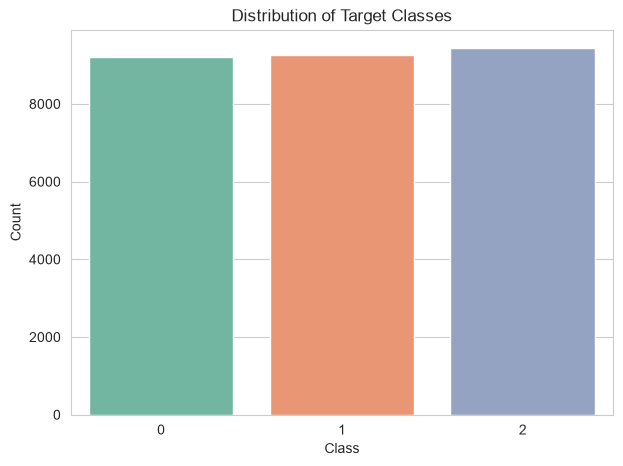

In [31]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=data,
    x='Class',
    palette='Set2'
)

plt.title("Distribution of Target Classes")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

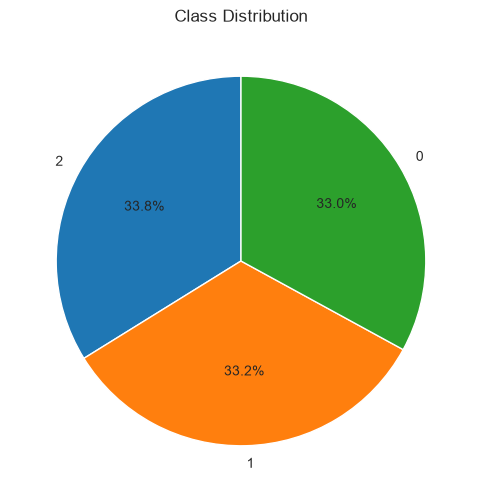

In [32]:
class_counts = data['Class'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Class Distribution")

plt.show()

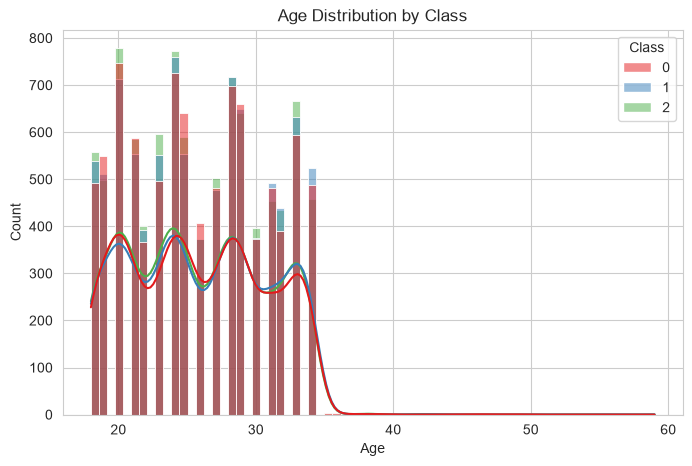

In [33]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=data,
    x='Age',
    hue='Class',
    kde=True,
    palette='Set1'
)

plt.title("Age Distribution by Class")

plt.show()

In [34]:
#Correlation Heatmap

#First convert categorical columns into numeric.

from sklearn.preprocessing import LabelEncoder

df_encoded = data.copy()

le = LabelEncoder()

for col in df_encoded.columns:

    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

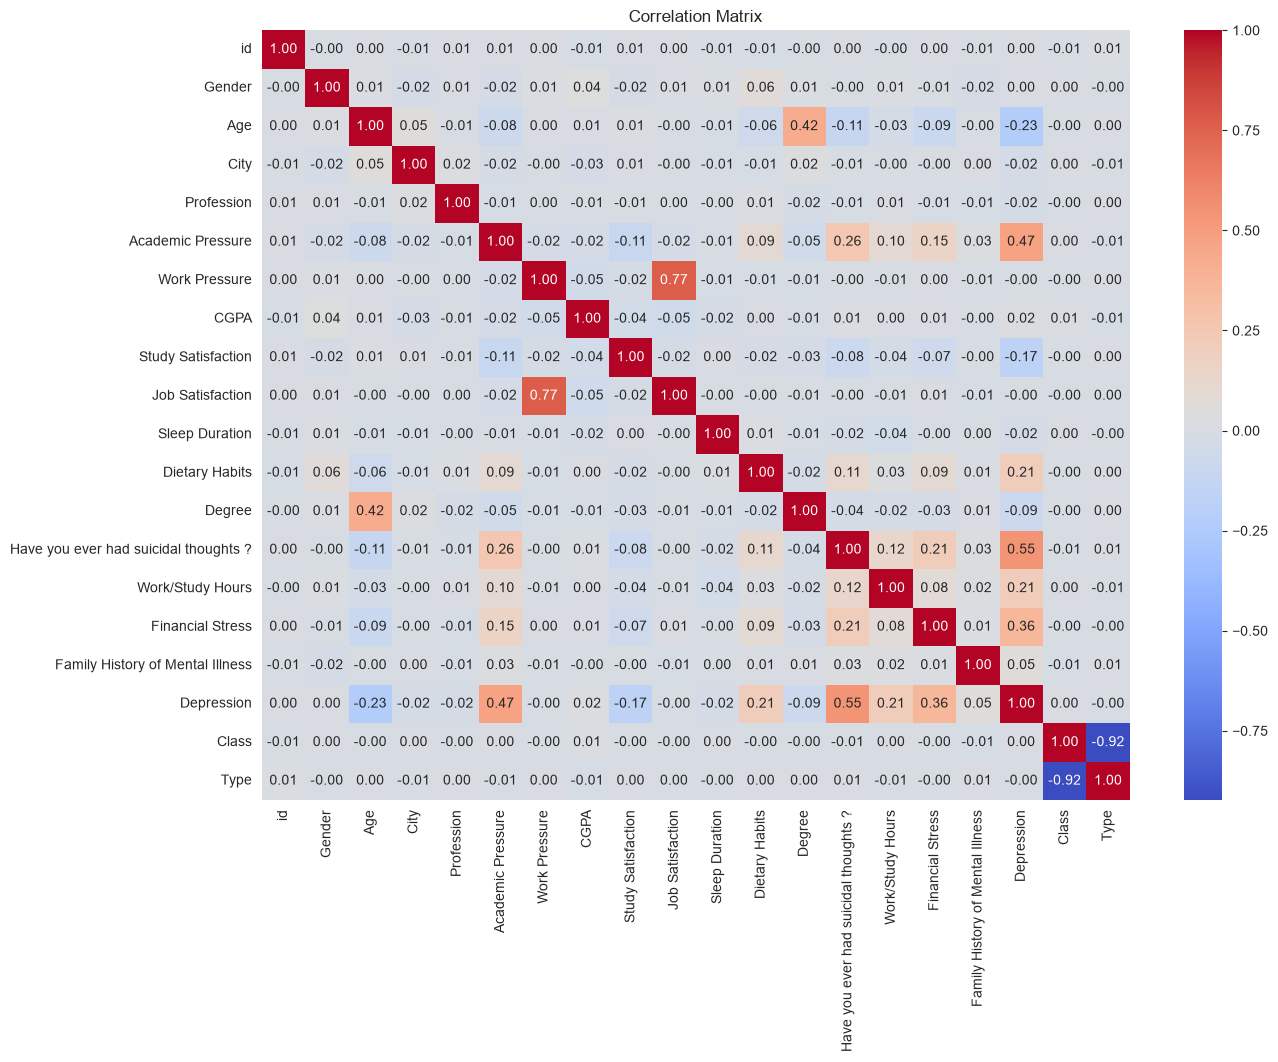

In [35]:
plt.figure(figsize=(14,10))

sns.heatmap(
    df_encoded.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [36]:
#Display the count of each class

# Count records in each class
class_count = data['Class'].value_counts()

print("Number of records in each class:")
print(class_count)

Number of records in each class:
Class
2    9439
1    9266
0    9196
Name: count, dtype: int64


In [37]:
#Display count and percentage
class_summary = pd.DataFrame({
    'Count': data['Class'].value_counts(),
    'Percentage (%)': round(data['Class'].value_counts(normalize=True) * 100, 2)
})

print(class_summary)

       Count  Percentage (%)
Class                       
2       9439           33.83
1       9266           33.21
0       9196           32.96


In [38]:
print(data[["Type"]].head(10))

   Type
0     1
1     4
2     4
3     2
4     1
5     3
6     1
7     3
8     3
9     1


In [39]:
# -------------------------------------------
# Features and Target
# -------------------------------------------

X = data.drop("Type", axis=1)

y = data["Type"]

In [40]:
# -------------------------------------------
# Train-Test Split
# -------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [41]:
# -------------------------------------------
# Build Random Forest Classifier for Type
# -------------------------------------------

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

In [42]:
# -------------------------------------------
# Prediction
# -------------------------------------------

y_pred = model.predict(X_test)


In [43]:
y_pred = model.predict(X_test)

# -------------------------------------------
# Evaluation
# -------------------------------------------

print("\nAccuracy :", accuracy_score(y_test, y_pred))

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, y_pred))


Accuracy : 0.5839455294750044

Classification Report

              precision    recall  f1-score   support

           0       0.59      0.89      0.71      1116
           1       0.39      0.07      0.12      1116
           2       0.60      0.99      0.75      1116
           3       0.36      0.05      0.09      1116
           4       0.61      0.91      0.73      1117

    accuracy                           0.58      5581
   macro avg       0.51      0.58      0.48      5581
weighted avg       0.51      0.58      0.48      5581


Confusion Matrix

[[ 993  123    0    0    0]
 [ 692   82  342    0    0]
 [   0    4 1109    3    0]
 [   0    2  395   58  661]
 [   0    1    0   99 1017]]


In [44]:
for col, encoder in label_encoders.items():
    print(f"\n{col}")
    for original, encoded in zip(encoder.classes_, encoder.transform(encoder.classes_)):
        print(f"{original} --> {encoded}")


Gender
Female --> 0
Male --> 1

City
'Less Delhi' --> 0
'Less than 5 Kalyan' --> 1
3.0 --> 2
Agra --> 3
Ahmedabad --> 4
Bangalore --> 5
Bhavna --> 6
Bhopal --> 7
Chennai --> 8
City --> 9
Delhi --> 10
Faridabad --> 11
Gaurav --> 12
Ghaziabad --> 13
Harsh --> 14
Harsha --> 15
Hyderabad --> 16
Indore --> 17
Jaipur --> 18
Kalyan --> 19
Kanpur --> 20
Khaziabad --> 21
Kibara --> 22
Kolkata --> 23
Lucknow --> 24
Ludhiana --> 25
M.Com --> 26
M.Tech --> 27
ME --> 28
Meerut --> 29
Mihir --> 30
Mira --> 31
Mumbai --> 32
Nagpur --> 33
Nalini --> 34
Nalyan --> 35
Nandini --> 36
Nashik --> 37
Patna --> 38
Pune --> 39
Rajkot --> 40
Rashi --> 41
Reyansh --> 42
Saanvi --> 43
Srinagar --> 44
Surat --> 45
Thane --> 46
Vaanya --> 47
Vadodara --> 48
Varanasi --> 49
Vasai-Virar --> 50
Visakhapatnam --> 51

Profession
'Civil Engineer' --> 0
'Content Writer' --> 1
'Digital Marketer' --> 2
'Educational Consultant' --> 3
'UX/UI Designer' --> 4
Architect --> 5
Chef --> 6
Doctor --> 7
Entrepreneur --> 8
Lawyer -

In [45]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)

print(importance)

                                  Feature  Importance
18                                  Class    0.347434
0                                      id    0.095379
7                                    CGPA    0.088579
3                                    City    0.070698
2                                     Age    0.060088
12                                 Degree    0.059036
14                       Work/Study Hours    0.056873
8                      Study Satisfaction    0.037790
15                       Financial Stress    0.036742
5                       Academic Pressure    0.034484
10                         Sleep Duration    0.032600
11                         Dietary Habits    0.023859
16       Family History of Mental Illness    0.015586
1                                  Gender    0.015402
13  Have you ever had suicidal thoughts ?    0.013661
17                             Depression    0.011404
4                              Profession    0.000332
9                        Job

In [46]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

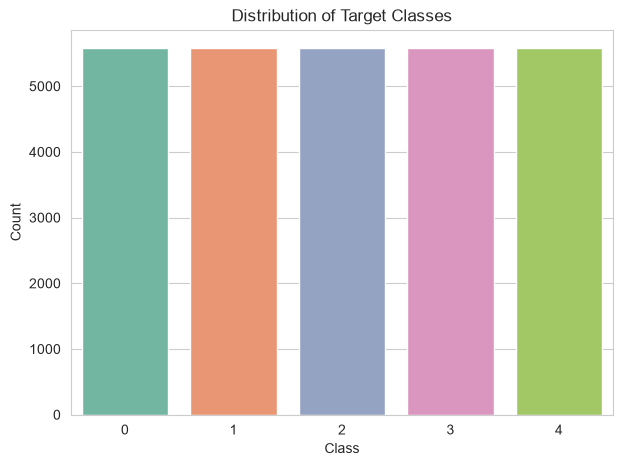

In [47]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=data,
    x='Type',
    palette='Set2'
)

plt.title("Distribution of Target Classes")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

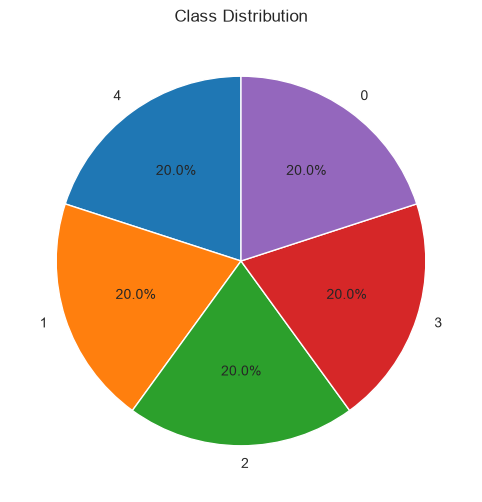

In [48]:
class_counts = data['Type'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Class Distribution")

plt.show()

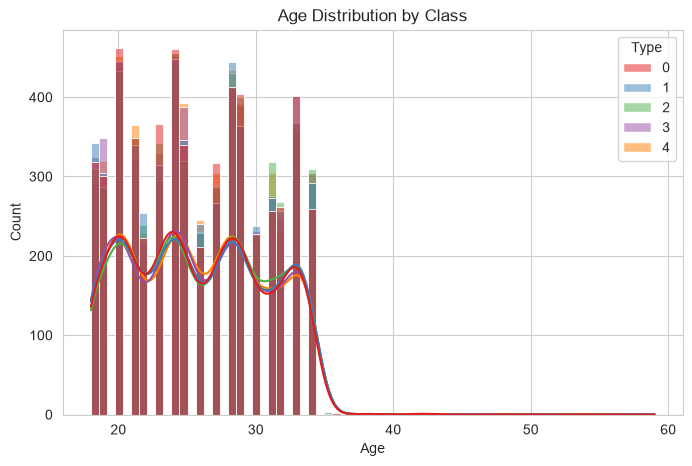

In [49]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=data,
    x='Age',
    hue='Type',
    kde=True,
    palette='Set1'
)

plt.title("Age Distribution by Class")

plt.show()

In [50]:
#Correlation Heatmap

#First convert categorical columns into numeric.

from sklearn.preprocessing import LabelEncoder

df_encoded = data.copy()

le = LabelEncoder()

for col in df_encoded.columns:

    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

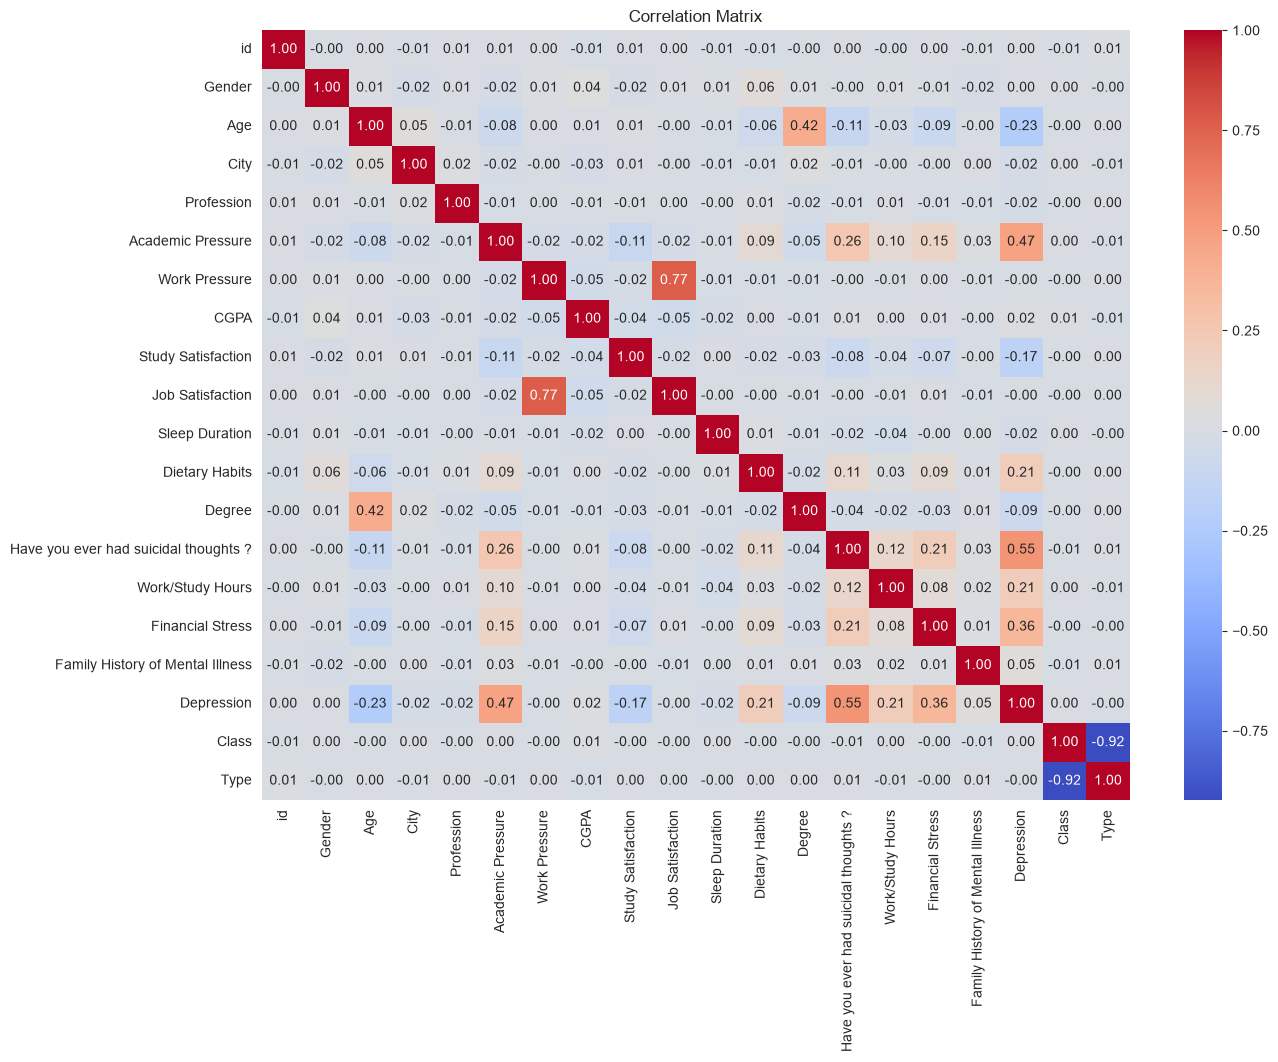

In [51]:
plt.figure(figsize=(14,10))

sns.heatmap(
    df_encoded.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [52]:
#Display the count of each class

# Count records in each class
class_count = data['Type'].value_counts()

print("Number of records in each class:")
print(class_count)

Number of records in each class:
Type
4    5581
1    5580
2    5580
3    5580
0    5580
Name: count, dtype: int64


In [53]:
#Display count and percentage
class_summary = pd.DataFrame({
    'Count': data['Type'].value_counts(),
    'Percentage (%)': round(data['Class'].value_counts(normalize=True) * 100, 2)
})

print(class_summary)

   Count  Percentage (%)
0   5580           32.96
1   5580           33.21
2   5580           33.83
3   5580             NaN
4   5581             NaN


In [54]:
from sklearn.preprocessing import LabelEncoder

data.columns = data.columns.str.strip()

le = LabelEncoder()

for col in data.columns:
    if data[col].dtype == "object":
        data[col] = le.fit_transform(data[col].astype(str))

In [55]:
X = data.drop("Type", axis=1)
y = data["Type"]

In [56]:
print(data.dtypes)

id                                         int64
Gender                                     int64
Age                                      float64
City                                       int64
Profession                                 int64
Academic Pressure                        float64
Work Pressure                            float64
CGPA                                     float64
Study Satisfaction                       float64
Job Satisfaction                         float64
Sleep Duration                             int64
Dietary Habits                             int64
Degree                                     int64
Have you ever had suicidal thoughts ?      int64
Work/Study Hours                         float64
Financial Stress                           int64
Family History of Mental Illness           int64
Depression                                 int64
Class                                      int64
Type                                       int64
dtype: object


In [57]:
for col, encoder in label_encoders.items():
    print(f"\n{col}")
    for original, encoded in zip(encoder.classes_, encoder.transform(encoder.classes_)):
        print(f"{original} --> {encoded}")
        


Gender
Female --> 0
Male --> 1

City
'Less Delhi' --> 0
'Less than 5 Kalyan' --> 1
3.0 --> 2
Agra --> 3
Ahmedabad --> 4
Bangalore --> 5
Bhavna --> 6
Bhopal --> 7
Chennai --> 8
City --> 9
Delhi --> 10
Faridabad --> 11
Gaurav --> 12
Ghaziabad --> 13
Harsh --> 14
Harsha --> 15
Hyderabad --> 16
Indore --> 17
Jaipur --> 18
Kalyan --> 19
Kanpur --> 20
Khaziabad --> 21
Kibara --> 22
Kolkata --> 23
Lucknow --> 24
Ludhiana --> 25
M.Com --> 26
M.Tech --> 27
ME --> 28
Meerut --> 29
Mihir --> 30
Mira --> 31
Mumbai --> 32
Nagpur --> 33
Nalini --> 34
Nalyan --> 35
Nandini --> 36
Nashik --> 37
Patna --> 38
Pune --> 39
Rajkot --> 40
Rashi --> 41
Reyansh --> 42
Saanvi --> 43
Srinagar --> 44
Surat --> 45
Thane --> 46
Vaanya --> 47
Vadodara --> 48
Varanasi --> 49
Vasai-Virar --> 50
Visakhapatnam --> 51

Profession
'Civil Engineer' --> 0
'Content Writer' --> 1
'Digital Marketer' --> 2
'Educational Consultant' --> 3
'UX/UI Designer' --> 4
Architect --> 5
Chef --> 6
Doctor --> 7
Entrepreneur --> 8
Lawyer -

In [58]:
#Correlation Heatmap

#First convert categorical columns into numeric.

from sklearn.preprocessing import LabelEncoder

df_encoded = data.copy()

le = LabelEncoder()

for col in df_encoded.columns:

    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

In [59]:
# Create new student sample profile for prediction
new_student = pd.DataFrame({
    'id': [140700],
    'Gender': ['Male'],
    'Age': [21],
    'City': ['Mumbai'],
    'Profession': ['Student'],
    'Academic Pressure': [5],
    'Work Pressure': [1],
    'CGPA': [7.8],
    'Study Satisfaction': [2],
    'Job Satisfaction': [0],
    'Sleep Duration': ['Less than 5 hours'],
    'Dietary Habits': ['Unhealthy'],
    'Degree': ['B.Tech'],
    'Have you ever had suicidal thoughts ?': ['Yes'],
    'Work/Study Hours': [10],
    'Financial Stress': [4.0],
    'Family History of Mental Illness': ['Yes'],
    'Depression': [1],
    'Class': ['Yes']
})
print('New Student Profile Created:')
print(new_student)

New Student Profile Created:
       id Gender  Age  ... Family History of Mental Illness  Depression Class
0  140700   Male   21  ...                              Yes           1   Yes

[1 rows x 19 columns]


In [60]:
# Encode categorical features of new student using fitted encoders
new_student_encoded = new_student.copy()
for col, encoder in label_encoders.items():
    if col in new_student_encoded.columns and col != 'Type':
        val = str(new_student_encoded[col].iloc[0])
        if val in list(encoder.classes_):
            new_student_encoded[col] = encoder.transform([val])[0]
        else:
            new_student_encoded[col] = 0

print('Encoded Profile for Model Inference:')
print(new_student_encoded)

Encoded Profile for Model Inference:
       id  Gender  ...  Depression  Class
0  140700       1  ...           1      2

[1 rows x 19 columns]


In [61]:
# Predict Depression Type for new student
features = [col for col in X_train.columns]
prediction = model.predict(new_student_encoded[features])
predicted_label = label_encoders['Type'].inverse_transform(prediction)[0] if 'Type' in label_encoders else prediction[0]

print('Predicted Depression Type (Encoded Code):', prediction[0])
print('Predicted Depression Type (Original Label):', predicted_label)

Predicted Depression Type (Encoded Code): 0
Predicted Depression Type (Original Label): DE
